In [10]:
import json
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath("."))
from global_config import RESULTS_DIR

#figures saved in this folder
FIGURES_DIR = RESULTS_DIR.parent / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def load_report(filename):
    with open(RESULTS_DIR / filename, "r") as f:
        return json.load(f)

columns = ["accuracy", "precision", "recall", "f1", "auc_roc", "f1_ci_low", "f1_ci_high"]

Experiment 1: Baseline models 

,accuracy,precision,recall,f1,auc_roc,f1_ci_low,f1_ci_high
XGBoost,0.9317,0.9357,0.9316,0.9336,0.9910,0.9159,0.9501
SVM,0.9351,0.9521,0.9205,0.9360,0.9822,0.9184,0.9537
DistilBERT,0.9945,0.9958,0.9930,0.9944,0.9998,0.9930,0.9957
TF-IDF + LogReg,0.9793,0.9777,0.9803,0.9790,0.9981,0.9764,0.9818


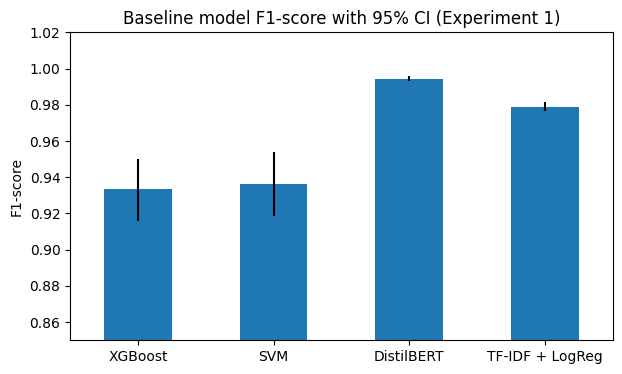

In [11]:
# put four reports into one table with one row per model
names = ["XGBoost", "SVM", "DistilBERT", "TF-IDF + LogReg"]
reports = [
    load_report("baseline_xgboost_report.json"),
    load_report("baseline_svm_report.json"),
    load_report("baseline_distilbert_report.json"),
    load_report("baseline_tfidf_logreg_report.json")]
table = pd.DataFrame(reports, index=names)[columns]
display(table.round(4))

#distance from F1 score to each end of confidence interval
errors = [table["f1"] - table["f1_ci_low"], table["f1_ci_high"] - table["f1"]]

#draw Figure 2
table["f1"].plot(kind="bar", yerr=errors, ylim=(0.85, 1.02), rot=0, figsize=(7, 4))
plt.title("Baseline model F1-score with 95% CI (Experiment 1)")
plt.ylabel("F1-score")
plt.savefig(FIGURES_DIR / "fig_results_exp1.png")
plt.show()

Experiment 2: Hybrid vs. single-modality

,accuracy,precision,recall,f1,auc_roc,f1_ci_low,f1_ci_high
"Structural only (XGBoost, pre-click features)",0.7992,0.8302,0.5238,0.6423,0.7977,0.5384,0.7296
Semantic only (DistilBERT),0.9877,0.9880,0.9762,0.9820,0.9993,0.9625,1.0000
Hybrid (logistic regression meta-fusion),0.9918,1.0000,0.9762,0.9880,0.9970,0.9703,1.0000


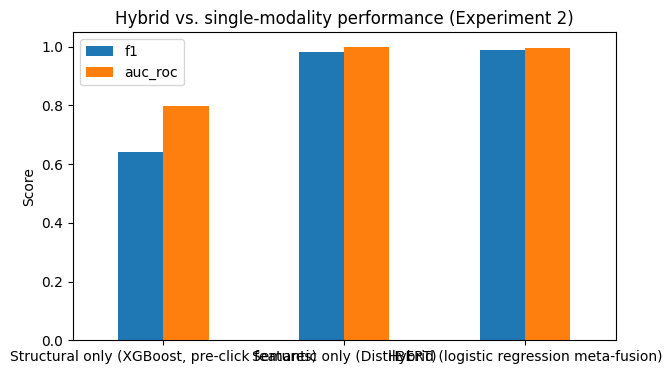

,structural_weight,semantic_weight,intercept
0,1.036,5.4107,-3.413


Decision threshold: 0.1


In [12]:
hybrid_data = load_report("hybrid_fusion_report.json")
baselines = hybrid_data["single_modality_baselines_on_same_test_population"]

#put 3 reports into one table and one row per model
names = ["Structural only (XGBoost, pre-click features)", "Semantic only (DistilBERT)", "Hybrid (logistic regression meta-fusion)"]
reports = [baselines["structural_only"], baselines["semantic_only"], hybrid_data["hybrid_report"]]
table = pd.DataFrame(reports, index=names)[columns]
display(table.round(4))

#F1 score and AUC ROC side by side for each model
table[["f1", "auc_roc"]].plot(kind="bar", rot=0, figsize=(7, 4))
plt.title("Hybrid vs. single-modality performance (Experiment 2)")
plt.ylabel("Score")
plt.savefig(FIGURES_DIR / "fig_results_exp2.png")
plt.show()

#print settings learned by logistic regression meta classifier
hybrid_report = hybrid_data["hybrid_report"]
display(pd.DataFrame([hybrid_report["meta_classifier_coefficients"]]).round(4))
print("Decision threshold:", hybrid_report["decision_threshold"])

 Feature importance of the structural model

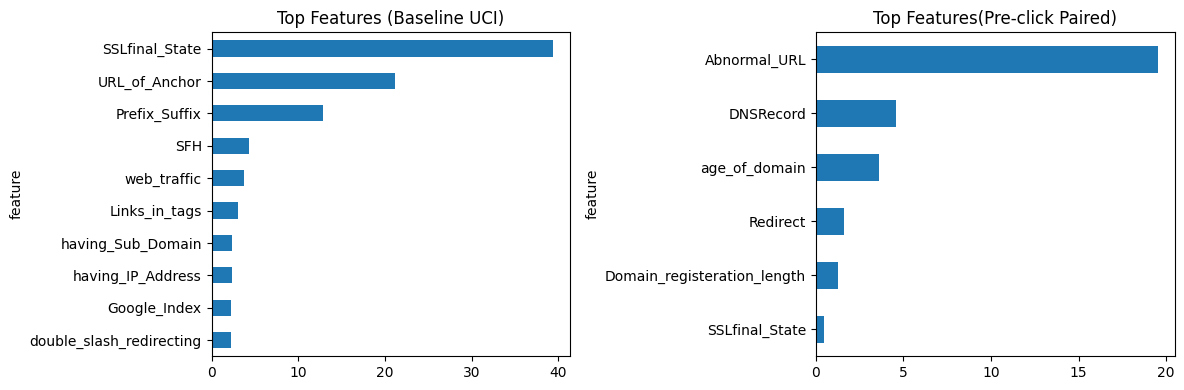

In [13]:
feature_data = load_report("feature_importance_report.json")

#keep 10 strongest features with gain above zero
uci = pd.DataFrame(feature_data["baseline_xgboost_uci"])
uci = uci[uci["gain"] > 0].head(10)[::-1] # [::-1] reverses order so biggest bar is at the top
paired = pd.DataFrame(feature_data["structural_pre_click_paired"])
paired = paired[paired["gain"] > 0].head(10)[::-1]

#UCI benchmark model on the left and preclick paired model on right
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
uci.plot(kind="barh", x="feature", y="gain", ax=left, title="Top Features (Baseline UCI)", legend=False)
paired.plot(kind="barh", x="feature", y="gain", ax=right, title="Top Features(Pre-click Paired)", legend=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_feature_importance.png")
plt.show()

Experiment 3: Latency benchmark

In [14]:
latency_data = load_report("latency_benchmark_report.json")
#5 pipeline stages, plus overall end to end time as last row
stages = latency_data["stages"]
stages["end_to_end"] = latency_data["end_to_end"]
table = pd.DataFrame(stages).T

#split confidence interval of median into low and high column
table["median_ci_low"] = table["median_ms_95ci"].str[0]
table["median_ci_high"] = table["median_ms_95ci"].str[1]
table = table[["mean_ms", "median_ms", "median_ci_low", "median_ci_high", "p95_ms", "min_ms", "max_ms"]]
print("n =", latency_data["n_samples"])
display(table.astype(float).round(2))

n = 145


,mean_ms,median_ms,median_ci_low,median_ci_high,p95_ms,min_ms,max_ms
dom_scrape_and_feature_extraction_ms,0.04,0.00,0.00,0.0,0.10,0.00,0.30
message_passing_ms,2.70,1.50,1.40,1.6,7.10,0.90,56.40
api_round_trip_ms,3593.71,2502.50,2278.80,2622.4,11086.00,836.70,17878.30
backend_processing_ms,3572.36,2480.89,2261.19,2606.2,11059.68,810.73,17859.62
badge_update_ms,0.12,0.10,0.10,0.1,0.20,0.00,0.20
end_to_end,3596.57,2503.70,2280.20,2623.7,11087.80,837.90,17879.90


Experiment 4: Adversarial evasion

,xgboost_recall,distilbert_recall,hybrid_recall
ssl_certificate_injection,0.806,0.994,0.994
domain_reputation_laundering,0.918,0.992,0.992
lexical_feature_normalisation,0.592,0.988,0.988
semantic_obfuscation,NaN,0.996,NaN


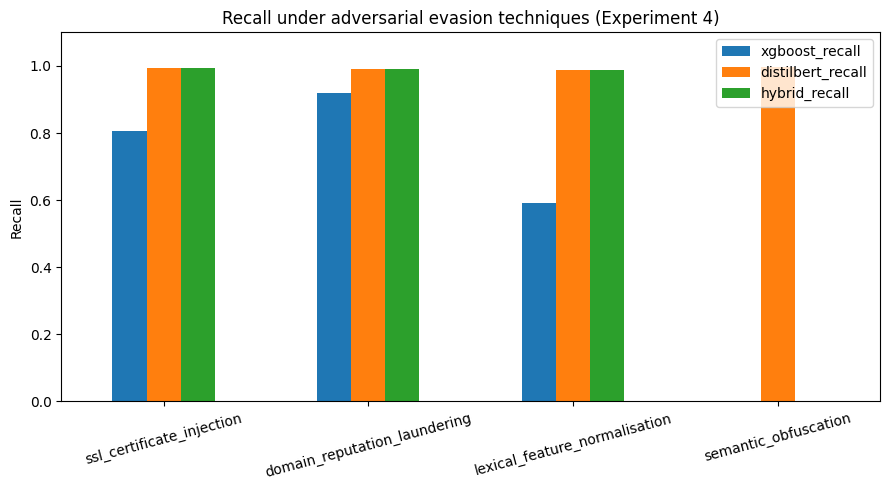

In [15]:
adv_data = load_report("adversarial_evaluation_report.json")

#put four techniques into one table with one row per technique
techniques = ["ssl_certificate_injection", "domain_reputation_laundering",
              "lexical_feature_normalisation", "semantic_obfuscation"]
table = pd.DataFrame([adv_data[t] for t in techniques], index=techniques)
table = table[["xgboost_recall", "distilbert_recall", "hybrid_recall"]]
display(table)

#three bars, one per model, for each technique
table.plot(kind="bar", rot=15, ylim=(0, 1.1), figsize=(9, 5))
plt.title("Recall under adversarial evasion techniques (Experiment 4)")
plt.ylabel("Recall")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_results_exp4.png")
plt.show()